# ***Importing Libraries***

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
import warnings
warnings.filterwarnings('ignore')

SEED = 42

# ***Exploratory Data Analysis (EDA)***

In [2]:
df = sns.load_dataset('penguins')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
df.tail()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,Male


In [4]:
df.shape

(344, 7)

In [5]:
df.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')

In [6]:
df.dtypes

,0
species,object
island,object
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [8]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.isnull().sum() / df.shape[0] * 100

,0
species,0.000000
island,0.000000
bill_length_mm,0.581395
bill_depth_mm,0.581395
flipper_length_mm,0.581395
body_mass_g,0.581395
sex,3.197674


In [11]:
df['species'].value_counts()

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


# ***Data Visualization***

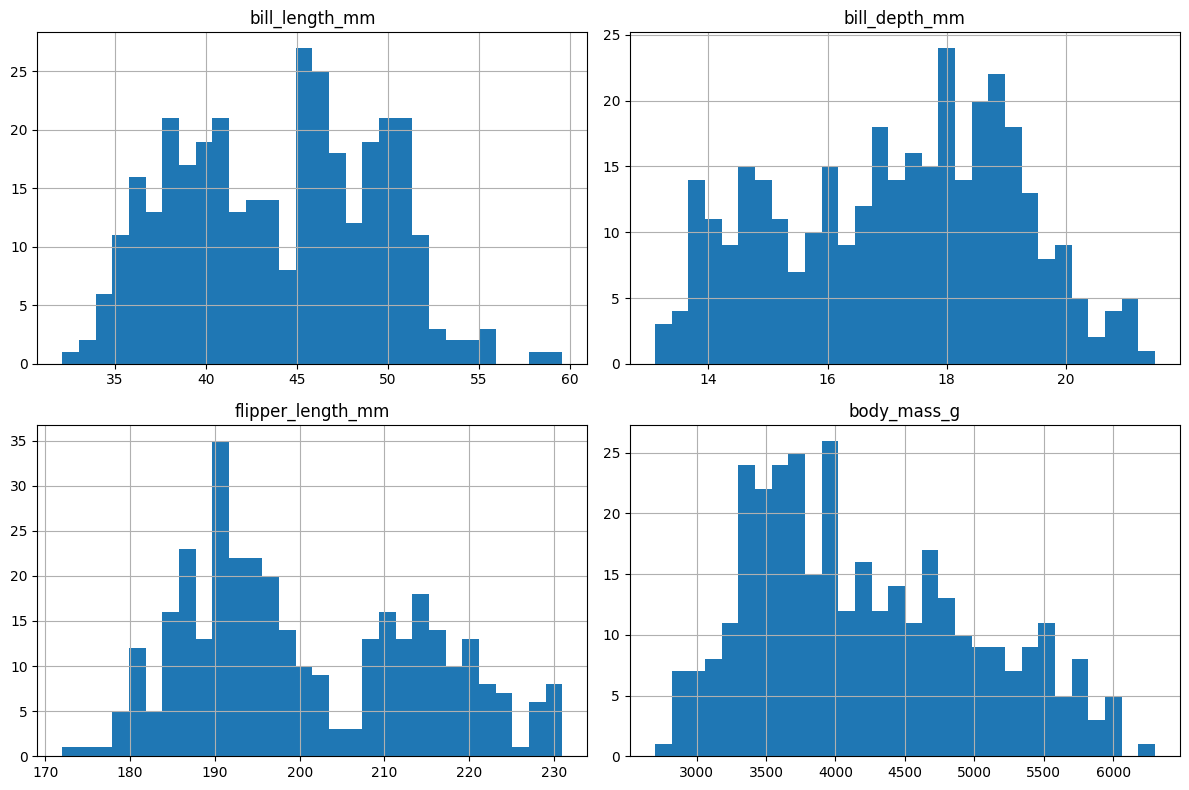

In [12]:
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

df[features].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

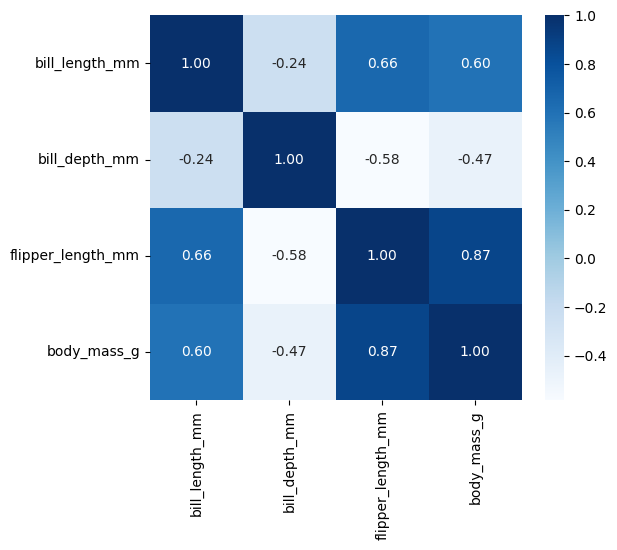

In [13]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[features].corr(), annot=True, fmt='.2f', cmap='Blues')
plt.show()

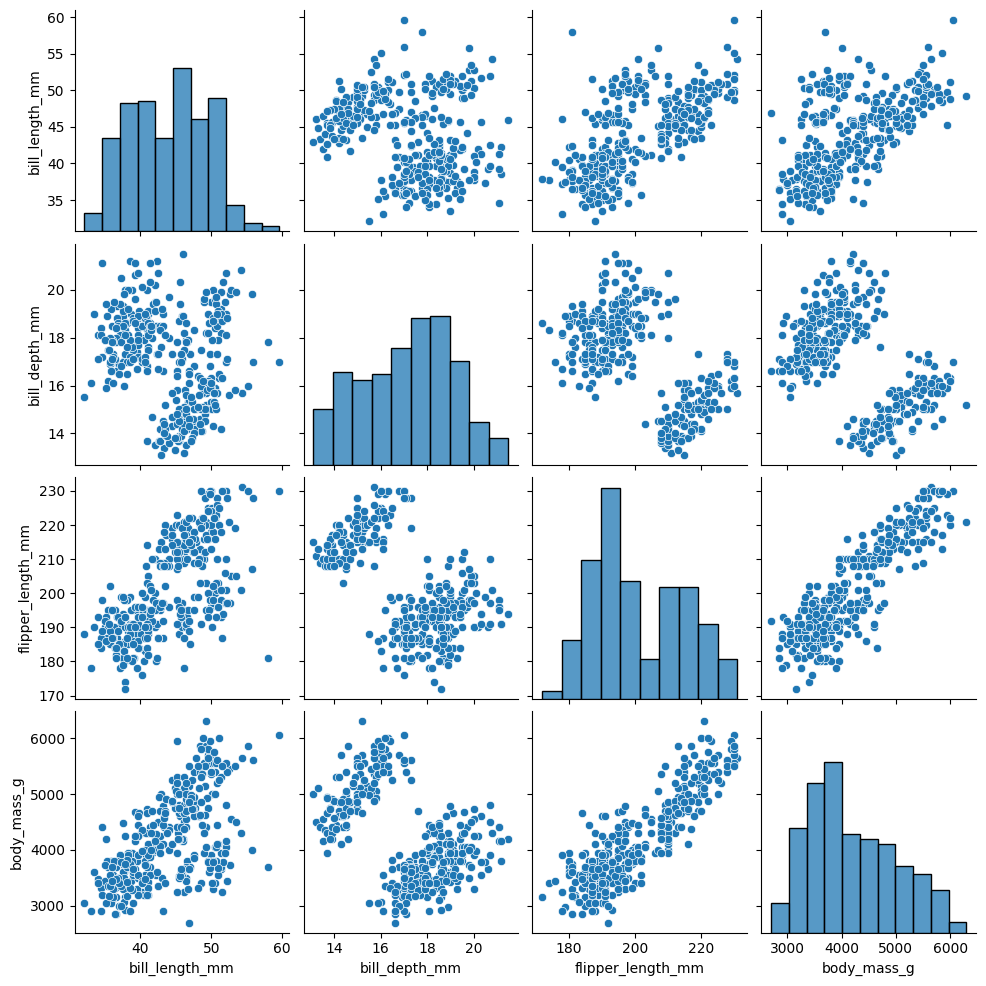

In [14]:
sns.pairplot(df[features])
plt.show()

# ***Data Preprocessing***

In [15]:
df = df.dropna().reset_index(drop=True)
df.shape

(333, 7)

In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])
X_scaled.shape

(333, 4)

In [17]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
print(pca.explained_variance_ratio_)

[0.68633893 0.19452929]


# ***KMeans Model***

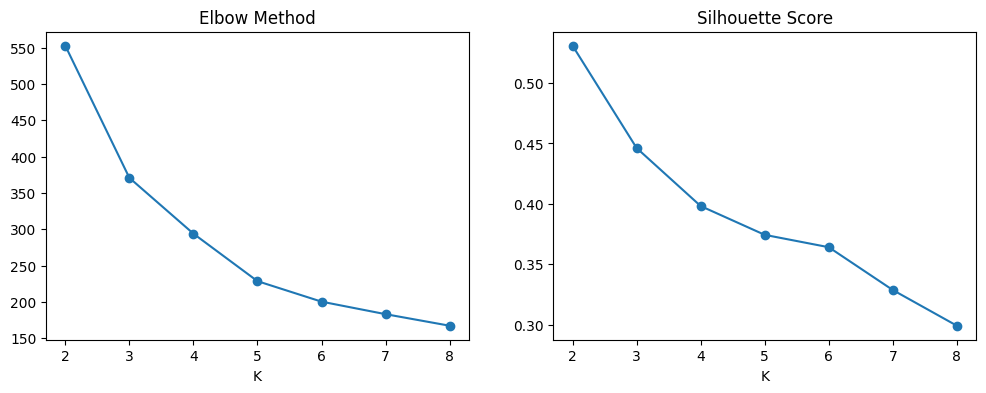

In [18]:
inertias = []
silhouettes = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(range(2, 9), inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('K')

plt.subplot(1, 2, 2)
plt.plot(range(2, 9), silhouettes, marker='o')
plt.title('Silhouette Score')
plt.xlabel('K')

plt.show()

In [19]:
kmeans = KMeans(n_clusters=3, random_state=SEED, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
pd.Series(kmeans_labels).value_counts().sort_index()

,count
0,129
1,119
2,85


# ***Hierarchical Clustering Model***

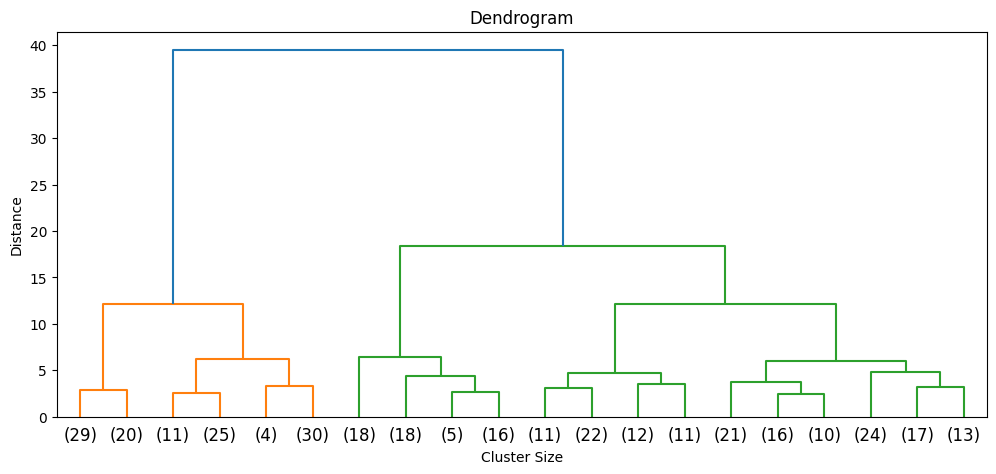

In [20]:
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=20)
plt.title('Dendrogram')
plt.xlabel('Cluster Size')
plt.ylabel('Distance')
plt.show()

In [21]:
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)
pd.Series(agg_labels).value_counts().sort_index()

,count
0,119
1,157
2,57


# ***DBSCAN Model***

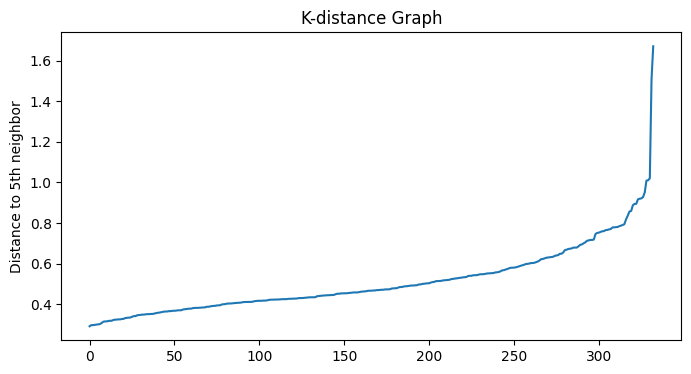

In [22]:
neighbors = NearestNeighbors(n_neighbors=5).fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)

plt.figure(figsize=(8, 4))
plt.plot(np.sort(distances[:, 4]))
plt.title('K-distance Graph')
plt.ylabel('Distance to 5th neighbor')
plt.show()

In [23]:
dbscan = DBSCAN(eps=0.6, min_samples=5)
db_labels = dbscan.fit_predict(X_scaled)
pd.Series(db_labels).value_counts().sort_index()

,count
-1,32
0,189
1,112


# ***Evaluating the Clusters***

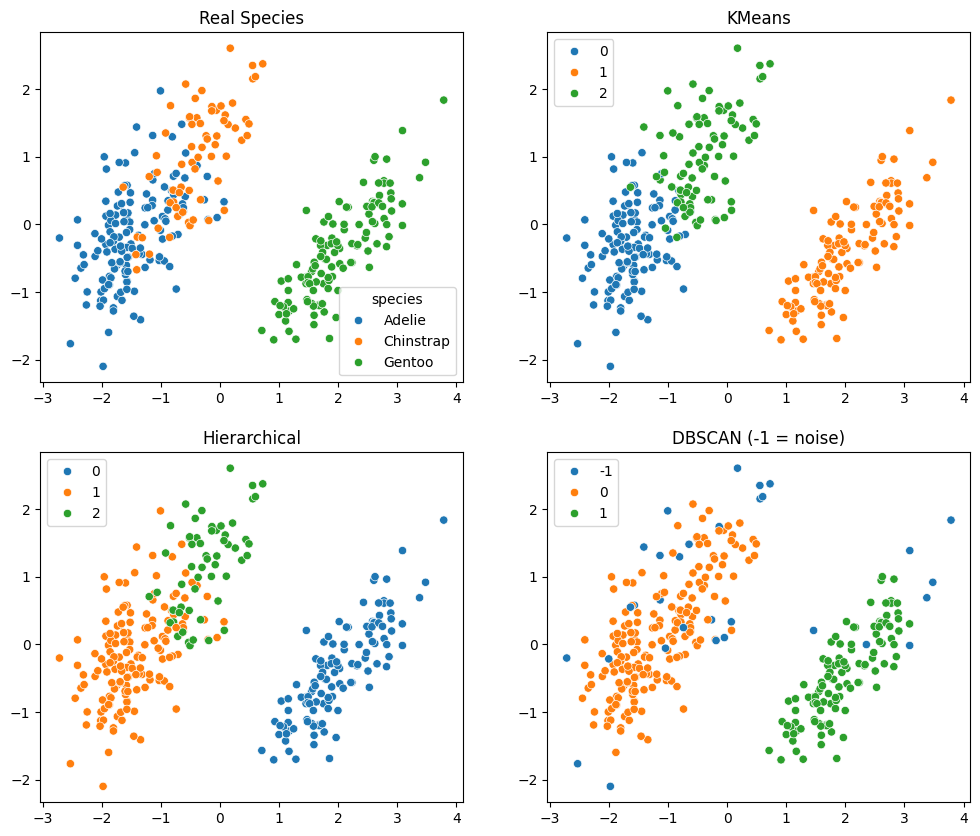

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['species'], palette='tab10', ax=axes[0, 0])
axes[0, 0].set_title('Real Species')

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels, palette='tab10', ax=axes[0, 1])
axes[0, 1].set_title('KMeans')

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=agg_labels, palette='tab10', ax=axes[1, 0])
axes[1, 0].set_title('Hierarchical')

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=db_labels, palette='tab10', ax=axes[1, 1])
axes[1, 1].set_title('DBSCAN (-1 = noise)')

plt.show()

In [25]:
df.assign(Cluster=kmeans_labels).groupby('Cluster')[features].mean()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
Cluster,,,,
0,38.276744,18.121705,188.627907,3593.798450
1,47.568067,14.996639,217.235294,5092.436975
2,47.662353,18.748235,196.917647,3898.235294


In [26]:
pd.crosstab(df['species'], kmeans_labels, rownames=['Species'], colnames=['Cluster'])

Cluster,0,1,2
Species,,,
Adelie,124,0,22
Chinstrap,5,0,63
Gentoo,0,119,0


In [27]:
pd.crosstab(df['species'], agg_labels, rownames=['Species'], colnames=['Cluster'])

Cluster,0,1,2
Species,,,
Adelie,0,146,0
Chinstrap,0,11,57
Gentoo,119,0,0


In [28]:
pd.crosstab(df['species'], db_labels, rownames=['Species'], colnames=['Cluster'])

Cluster,-1,0,1
Species,,,
Adelie,15,131,0
Chinstrap,10,58,0
Gentoo,7,0,112


# ***Model Comparison***

In [29]:
results = []
for name, labels in [("KMeans", kmeans_labels), ("Hierarchical", agg_labels), ("DBSCAN", db_labels)]:
    mask = labels != -1
    results.append({
        "Model": name,
        "Clusters": len(set(labels[mask])),
        "Noise Points": int((~mask).sum()),
        "Silhouette": silhouette_score(X_scaled[mask], labels[mask]),
        "Davies-Bouldin": davies_bouldin_score(X_scaled[mask], labels[mask]),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled[mask], labels[mask]),
        "ARI (vs species)": adjusted_rand_score(df['species'], labels)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="Silhouette", ascending=False)
results_df.reset_index(drop=True, inplace=True)
results_df

,Model,Clusters,Noise Points,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (vs species)
0,DBSCAN,2,32,0.556535,0.671878,498.451439,0.579397
1,Hierarchical,3,0,0.452098,0.850245,408.217170,0.913240
2,KMeans,3,0,0.446193,0.942010,427.772571,0.799421


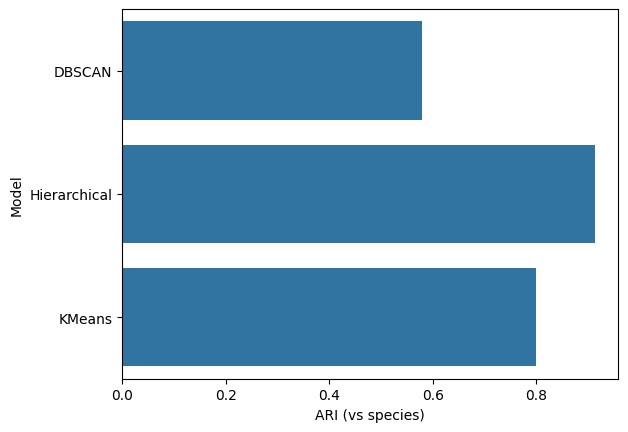

In [30]:
sns.barplot(x="ARI (vs species)", y="Model", data=results_df)
plt.show()